# Riesgos en cascada: un ejemplo con datos inventados

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/teoria-riesgos/blob/main/book/03_amenazas/314_riesgos_cascada.ipynb)

```{warning}
**Todos los datos de este cuaderno son inventados.** Los servicios, sus dependencias, las intensidades y los parámetros no corresponden a ninguna ciudad real. Sirve para ver **cómo se calcula** una cascada, con las ideas del [capítulo de cascadas y compuestos](../01_conceptos/15_cascada_compuestos.md). El segundo ejemplo es un modelo de juguete, no calibrado.
```

## Qué se calcula

Una cascada aparece cuando la falla de un servicio provoca la de otros que dependen de él. El capítulo de cascadas y compuestos la describe como una cadena (detonante, impacto primario, falla de sistemas interdependientes, crisis secundarias) y propone mapear detonantes y consecuencias y modelar las interdependencias entre sectores. Aquí se hace en dos partes:

1. **Una red de servicios interdependientes** (energía, agua, comunicaciones, vía, hospital) sometida a tres escenarios. Se compara la interrupción **solo por daño directo** con la interrupción **con cascada**.
2. **Un bucle de retroalimentación** como el de las inundaciones de Limbe: el daño reduce la inversión y eso aumenta el daño siguiente.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr

rng = np.random.default_rng(7)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. La red de servicios (inventada)

Cada servicio tiene dos cosas: **qué daño directo puede sufrir** por la amenaza (según su intensidad en el sitio) y **de qué otros servicios depende**. Cada dependencia lleva una **autonomía** en horas: el tiempo que el servicio aguanta con reservas (generador, tanque, baterías) después de que falla aquello de lo que depende. Con autonomía 0 la falla es inmediata.

In [2]:
SERVICIOS = ["Subestación eléctrica", "Planta de agua", "Torre de comunicaciones", "Puente vial",
             "Centro de emergencias", "Hospital", "Albergue", "Servicio de agua (barrio)",
             "Servicio eléctrico (barrio)"]

# dependencias: (servicio, depende de, autonomía en horas)
DEPENDENCIAS = [
    ("Planta de agua", "Subestación eléctrica", 4),
    ("Torre de comunicaciones", "Subestación eléctrica", 12),     # baterías
    ("Centro de emergencias", "Subestación eléctrica", 24),        # planta propia
    ("Centro de emergencias", "Torre de comunicaciones", 0),
    ("Hospital", "Subestación eléctrica", 48),                     # generador
    ("Hospital", "Planta de agua", 12),                            # tanque
    ("Hospital", "Puente vial", 72),                               # reservas, acceso de insumos
    ("Albergue", "Planta de agua", 8),
    ("Albergue", "Puente vial", 24),
    ("Servicio de agua (barrio)", "Planta de agua", 0),
    ("Servicio eléctrico (barrio)", "Subestación eléctrica", 0),
]

# Intensidades en el sitio de cada servicio, por escenario (inventadas):
# profundidad de inundación (m) y aceleración (g). Nan = no aplica.
SITIOS = pd.DataFrame({
    "inund_T25":  [0.3, 0.1, 0.0, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0],
    "inund_T100": [0.9, 0.4, 0.0, 1.4, 0.0, 0.0, 0.2, 0.0, 0.0],
    "pga_T475":   [0.22, 0.20, 0.25, 0.28, 0.20, 0.18, 0.18, 0.0, 0.0],
}, index=SERVICIOS)

# Fragilidad: mediana y dispersión del umbral de falla directa (lognormal), por servicio
FRAGILIDAD = pd.DataFrame({
    "mediana_inund": [1.0, 1.2, 3.0, 1.6, 2.0, 2.0, 1.5, 1.0, 1.0],   # m
    "mediana_pga":   [0.45, 0.50, 0.40, 0.55, 0.60, 0.65, 0.45, 0.50, 0.45],  # g
}, index=SERVICIOS)
BETA = 0.5

def prob_falla_directa(escenario):
    """Probabilidad de que cada servicio falle por daño directo en el escenario."""
    if escenario.startswith("inund"):
        I, med = SITIOS[escenario], FRAGILIDAD.mediana_inund
    else:
        I, med = SITIOS[escenario], FRAGILIDAD.mediana_pga
    p = pd.Series(ndtr(np.log(np.clip(I, 1e-9, None) / med) / BETA), index=SERVICIOS)
    return p.where(I > 0, 0.0)

pd.DataFrame({e: prob_falla_directa(e) for e in SITIOS.columns}).round(2)

,inund_T25,inund_T100,pga_T475
Subestación eléctrica,0.01,0.42,0.08
Planta de agua,0.00,0.01,0.03
Torre de comunicaciones,0.00,0.00,0.17
Puente vial,0.01,0.39,0.09
Centro de emergencias,0.00,0.00,0.01
Hospital,0.00,0.00,0.01
Albergue,0.00,0.00,0.03
Servicio de agua (barrio),0.00,0.00,0.00
Servicio eléctrico (barrio),0.00,0.00,0.00


## 2. Propagar las fallas por el tiempo

Para cada simulación se sortea qué servicios fallan por **daño directo** (instante 0). Después se propaga: un servicio falla en el instante en que falla aquello de lo que depende **más su autonomía**, y se toma el instante más temprano entre todas sus dependencias. Se mide en un horizonte de 72 horas cuántas horas queda cada servicio fuera de funcionamiento.

Se supone, para simplificar, que las fallas directas son **independientes** entre servicios dados el escenario. En la realidad están correlacionadas por la amenaza (si una crecida llega a la subestación, probablemente llega también al puente cercano); eso se trata en el [análisis multiamenaza](313_analisis_multiamenaza.ipynb) con escenarios por periodo de retorno.

In [3]:
HORIZONTE = 72      # horas
IDX = {s: i for i, s in enumerate(SERVICIOS)}

def propagar(falla_directa):
    """falla_directa: vector booleano. Devuelve el instante de falla (h) de cada servicio (inf si no falla)."""
    t = np.where(falla_directa, 0.0, np.inf)
    cambio = True
    while cambio:                                   # relajación hasta que ninguna hora cambie
        cambio = False
        for serv, dep, autonomia in DEPENDENCIAS:
            candidato = t[IDX[dep]] + autonomia
            if candidato < t[IDX[serv]]:
                t[IDX[serv]] = candidato
                cambio = True
    return t

def simular(escenario, n=5000):
    p = prob_falla_directa(escenario).values
    horas_directo = np.zeros((n, len(SERVICIOS)))
    horas_cascada = np.zeros((n, len(SERVICIOS)))
    for k in range(n):
        directa = rng.random(len(SERVICIOS)) < p
        t_casc = propagar(directa)
        horas_directo[k] = np.where(directa, HORIZONTE, 0)
        horas_cascada[k] = np.clip(HORIZONTE - t_casc, 0, None)
    return horas_directo, horas_cascada

ESCENARIOS = {"inund_T25": "Lluvia, T = 25 años", "inund_T100": "Lluvia, T = 100 años", "pga_T475": "Sismo, T = 475 años"}
SIM = {e: simular(e) for e in ESCENARIOS}

In [4]:
filas = []
for e, nombre in ESCENARIOS.items():
    d, c = SIM[e]
    for i, s in enumerate(SERVICIOS):
        filas.append(dict(escenario=nombre, servicio=s,
                          horas_directo=d[:, i].mean(), horas_con_cascada=c[:, i].mean()))
res = pd.DataFrame(filas)
res["amplificación (×)"] = np.where(res.horas_directo > 0.05, res.horas_con_cascada / res.horas_directo, np.nan)
res.pivot(index="servicio", columns="escenario", values=["horas_directo", "horas_con_cascada"]).round(1)

horas_directo                      \
escenario                   Lluvia, T = 100 años Lluvia, T = 25 años   
servicio                                                               
Albergue                                     0.0                 0.0   
Centro de emergencias                        0.0                 0.0   
Hospital                                     0.0                 0.0   
Planta de agua                               0.9                 0.0   
Puente vial                                 28.8                 0.6   
Servicio de agua (barrio)                    0.0                 0.0   
Servicio eléctrico (barrio)                  0.0                 0.0   
Subestación eléctrica                       29.2                 0.5   
Torre de comunicaciones                      0.0                 0.0   

                                                   horas_con_cascada  \
escenario                   Sismo, T = 475 años Lluvia, T = 100 años   
servicio                                                               
Albergue                                    2.2                 36.4   
Centro de emergencias                       0.8                 24.4   
Hospital                                    0.3                 23.3   
Planta de agua                              2.6                 28.3   
Puente vial                                 6.6                 28.8   
Servicio de agua (barrio)                   0.0                 28.3   
Servicio eléctrico (barrio)                 0.0                 29.2   
Subestación eléctrica                       5.8                 29.2   
Torre de comunicaciones                    12.4                 24.4   

                                                                     
escenario                   Lluvia, T = 25 años Sismo, T = 475 años  
servicio                                                             
Albergue                                    0.8                12.8  
Centro de emergencias                       0.4                16.9  
Hospital                                    0.4                 6.8  
Planta de agua                              0.5                 7.9  
Puente vial                                 0.6                 6.6  
Servicio de agua (barrio)                   0.5                 7.9  
Servicio eléctrico (barrio)                 0.5                 5.8  
Subestación eléctrica                       0.5                 5.8  
Torre de comunicaciones                     0.4                16.3

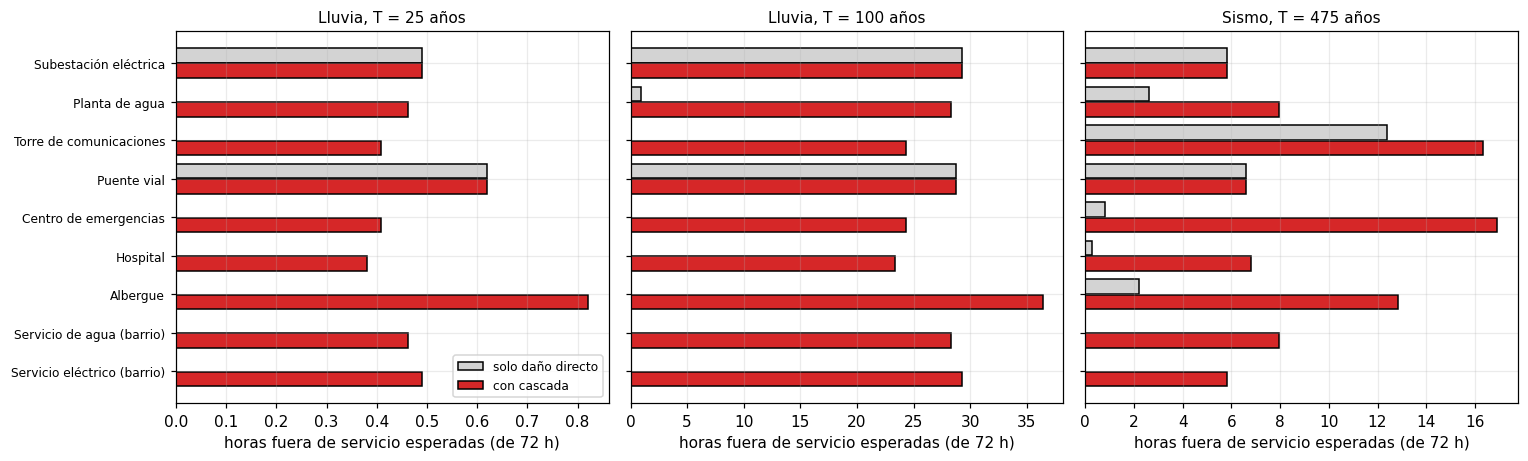

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
orden = SERVICIOS[::-1]
for a, (e, nombre) in zip(ax, ESCENARIOS.items()):
    sub = res[res.escenario == nombre].set_index("servicio").loc[orden]
    y = np.arange(len(orden))
    a.barh(y + 0.2, sub.horas_directo, height=0.38, color="lightgray", edgecolor="k", label="solo daño directo")
    a.barh(y - 0.2, sub.horas_con_cascada, height=0.38, color="tab:red", edgecolor="k", label="con cascada")
    a.set_yticks(y); a.set_yticklabels(orden, fontsize=8); a.set_title(nombre, fontsize=10)
    a.set_xlabel(f"horas fuera de servicio esperadas (de {HORIZONTE} h)")
ax[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 3. ¿Qué cambia con la cascada?

El hospital casi nunca falla por daño directo (su fragilidad es baja), pero **depende de tres servicios**. La siguiente celda mide la probabilidad de que pase **24 horas o más fuera de servicio** con y sin cascada. Un análisis que solo mira el daño directo subestima este riesgo.

In [6]:
tabla = []
for e, nombre in ESCENARIOS.items():
    d, c = SIM[e]
    for s in ["Hospital", "Centro de emergencias", "Albergue"]:
        i = IDX[s]
        tabla.append({"escenario": nombre, "servicio": s,
                      "P(≥24 h fuera), solo directo": (d[:, i] >= 24).mean(),
                      "P(≥24 h fuera), con cascada": (c[:, i] >= 24).mean()})
pd.DataFrame(tabla).round(3)

,escenario,servicio,"P(≥24 h fuera), solo directo","P(≥24 h fuera), con cascada"
0,"Lluvia, T = 25 años",Hospital,0.000,0.007
1,"Lluvia, T = 25 años",Centro de emergencias,0.000,0.007
2,"Lluvia, T = 25 años",Albergue,0.000,0.015
3,"Lluvia, T = 100 años",Hospital,0.000,0.415
4,"Lluvia, T = 100 años",Centro de emergencias,0.000,0.406
5,"Lluvia, T = 100 años",Albergue,0.000,0.654
6,"Sismo, T = 475 años",Hospital,0.004,0.118
7,"Sismo, T = 475 años",Centro de emergencias,0.011,0.246
8,"Sismo, T = 475 años",Albergue,0.031,0.222


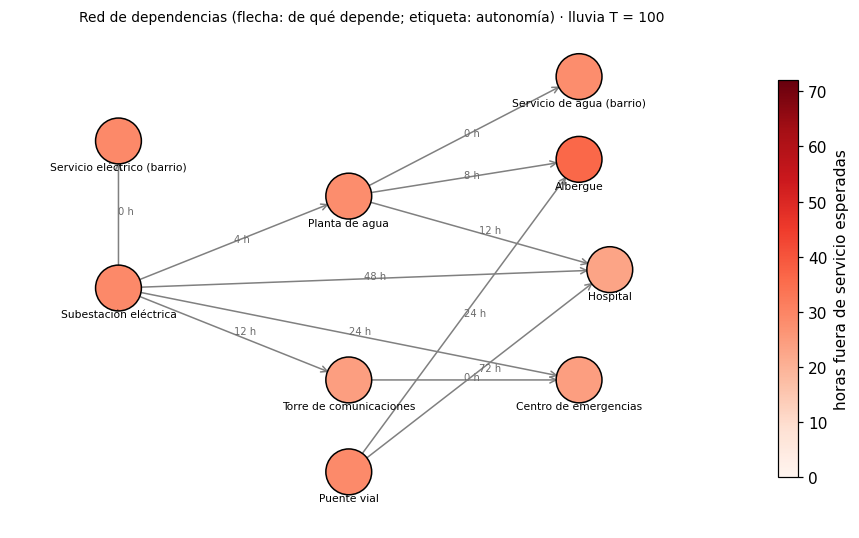

In [7]:
# Esquema de la red: color = horas fuera de servicio esperadas con cascada (escenario T = 100)
POS = {"Subestación eléctrica": (0, 2), "Planta de agua": (1.5, 3), "Torre de comunicaciones": (1.5, 1),
       "Puente vial": (1.5, 0), "Centro de emergencias": (3, 1), "Hospital": (3.2, 2.2), "Albergue": (3, 3.4),
       "Servicio de agua (barrio)": (3, 4.3), "Servicio eléctrico (barrio)": (0, 3.6)}
horas = res[res.escenario == ESCENARIOS["inund_T100"]].set_index("servicio").horas_con_cascada
fig, ax = plt.subplots(figsize=(8.5, 5))
for serv, dep, aut in DEPENDENCIAS:
    (x0, y0), (x1, y1) = POS[dep], POS[serv]
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color="gray", lw=1,
                shrinkA=14, shrinkB=14))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{aut} h", fontsize=6.5, color="dimgray")
sc = ax.scatter([POS[s][0] for s in SERVICIOS], [POS[s][1] for s in SERVICIOS],
                c=[horas[s] for s in SERVICIOS], cmap="Reds", vmin=0, vmax=HORIZONTE, s=900, edgecolor="k", zorder=3)
for s in SERVICIOS:
    ax.text(POS[s][0], POS[s][1] - 0.32, s, ha="center", fontsize=7)
plt.colorbar(sc, label="horas fuera de servicio esperadas", shrink=0.8)
ax.set_title("Red de dependencias (flecha: de qué depende; etiqueta: autonomía) · lluvia T = 100", fontsize=9)
ax.set_xlim(-0.7, 4.0); ax.set_ylim(-0.6, 4.8); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Un bucle de retroalimentación (modelo de juguete)

En Limbe, el capítulo de cascadas y compuestos describe una cascada económica que se cierra sobre sí misma: los drenajes bloqueados causan inundación, que interrumpe el transporte y los negocios, lo que reduce la inversión en infraestructura, y el ciclo continúa. Una evaluación que solo sigue la cadena hacia adelante no ve ese refuerzo.

Este modelo lo reproduce de forma mínima, **sin calibrar y con parámetros inventados**:

- $C_t$: capacidad de drenaje (1 = suficiente para la lluvia media alta).
- $R_t$: lluvia del año (aleatoria).
- Daño: $D_t = k \cdot \max(0, R_t - C_t)$.
- Inversión: $I_t = I_0 - \alpha D_t$ si la inversión depende del daño (el presupuesto se desvía a la recuperación), o $I_t = I_0$ si está **protegida**.
- Capacidad: $C_{t+1} = (1-\delta) C_t + \beta I_t$.

Se simulan 500 trayectorias de 30 años con la misma lluvia en los dos casos.

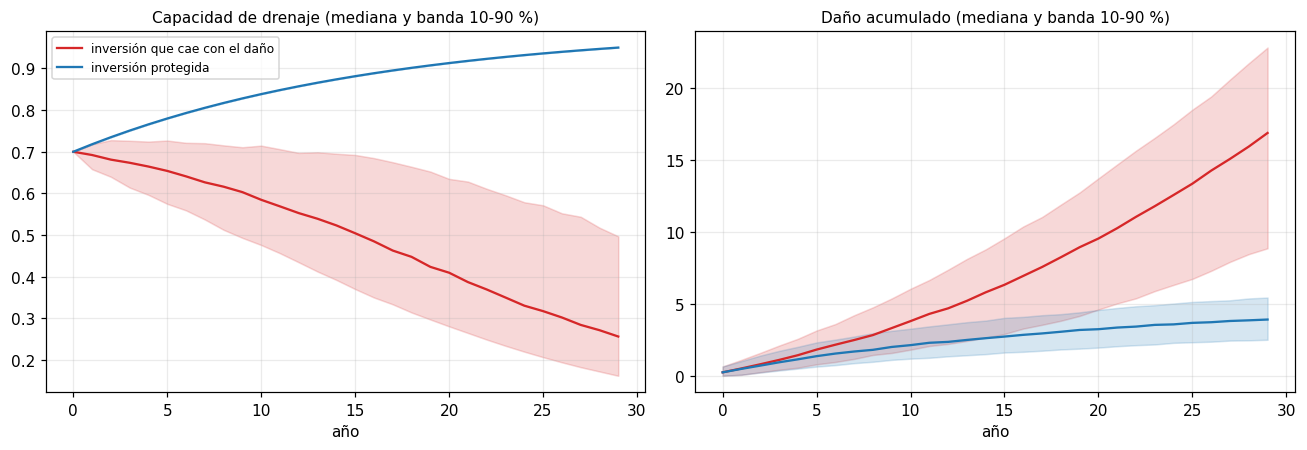

Daño acumulado a 30 años (mediana): con retroalimentación 16.9, con inversión protegida 3.9 (unidades arbitrarias).


In [8]:
ANIOS, N_SIM = 30, 500
C0, I0, DELTA, BETA_I, K, ALPHA = 0.70, 0.50, 0.06, 0.12, 1.5, 0.9

def trayectorias(retroalimentacion, lluvias):
    C = np.full(N_SIM, C0)
    Cs, Ds = [], []
    for t in range(ANIOS):
        R = lluvias[:, t]
        D = K * np.clip(R - C, 0, None)
        I = np.clip(I0 - ALPHA * D, 0, None) if retroalimentacion else np.full(N_SIM, I0)
        Cs.append(C.copy()); Ds.append(D)
        C = np.clip((1 - DELTA) * C + BETA_I * I, 0, 1.3)
    return np.array(Cs), np.array(Ds)            # (años, trayectorias)

lluvias = rng.lognormal(mean=np.log(0.85), sigma=0.22, size=(N_SIM, ANIOS))   # la MISMA lluvia en los dos casos
C_fb, D_fb = trayectorias(True, lluvias)
C_pr, D_pr = trayectorias(False, lluvias)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
anios = np.arange(ANIOS)
for (C, D, color, etiqueta) in [(C_fb, D_fb, "tab:red", "inversión que cae con el daño"),
                                (C_pr, D_pr, "tab:blue", "inversión protegida")]:
    for a, M, titulo in [(ax[0], C, "Capacidad de drenaje"), (ax[1], np.cumsum(D, axis=0), "Daño acumulado")]:
        a.plot(anios, np.median(M, axis=1), color=color, label=etiqueta)
        a.fill_between(anios, np.percentile(M, 10, axis=1), np.percentile(M, 90, axis=1), color=color, alpha=0.18)
        a.set_title(titulo + " (mediana y banda 10-90 %)", fontsize=10); a.set_xlabel("año")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Daño acumulado a 30 años (mediana): con retroalimentación {np.median(D_fb.sum(0)):.1f}, "
      f"con inversión protegida {np.median(D_pr.sum(0)):.1f} (unidades arbitrarias).")

La diferencia entre las dos curvas es el efecto del bucle: en el caso con retroalimentación, los años de lluvia fuerte recortan la inversión y la capacidad no se recupera. **Lo que enseña es una lección cualitativa**: las políticas que protegen la inversión en infraestructura cortan el bucle. Los números no significan nada fuera del juguete.

## 5. Cómo pasar a datos reales

| En este cuaderno | En un análisis real | Dónde se explica |
|---|---|---|
| `SERVICIOS`, `DEPENDENCIAS` | Inventario de líneas vitales de la ciudad y entrevistas con los operadores para fijar dependencias y autonomías | [Exposición](../04_vulnerabilidad/41_exposicion.md), [Cascadas y compuestos](../01_conceptos/15_cascada_compuestos.md) |
| `SITIOS` | Intensidades de los mapas de amenaza en el sitio de cada servicio, por escenario | [Inundación](305_inundacion.md), [Sismo](301_sismo.md) |
| `FRAGILIDAD` | Curvas de fragilidad de la literatura o de expertos para cada tipo de infraestructura | [Funciones de daño](../04_vulnerabilidad/42_funciones_dano.md) |
| Fallas independientes | Fallas correlacionadas por la misma amenaza (misma realización de intensidades) | [Análisis multiamenaza](313_analisis_multiamenaza.ipynb) |
| Bucle de Limbe | Un mapa de sistemas construido con los actores locales, y luego un modelo calibrado si hay datos | [Cascadas y compuestos](../01_conceptos/15_cascada_compuestos.md) |

Para el informe, la síntesis debe decir qué cascadas se cuantificaron, con qué supuestos de dependencia y autonomía, y cuáles quedaron solo descritas ([síntesis multiamenaza](../05_sintesis/51_sintesis_multiamenaza.md)).